<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [ ]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [4]:
NOMBRE = 'Cueva Evelyn'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Cueva Evelyn · semilla 866811
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 10.78%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-09-15 17:56:56-05:00,U0764,47.0,Pichincha,16,1637.21,transferencia,app,persona,502.66,1,3.3,1,0,17,0.307022
1,TX-000001,2026-09-13 16:57:00-05:00,U0444,26.0,Guayas,33,382.80,retiro_agente,app,efectivo,62.50,1,14.1,1,0,16,0.163271
2,TX-000002,2026-10-04 12:42:19-05:00,U0518,63.0,Manabí,49,655.71,transferencia,app,persona,80.52,0,10.2,1,0,12,0.122798
3,TX-000003,2026-10-27 19:18:23-05:00,U0175,42.0,Azuay,12,661.04,recarga,app,telefonia,20.52,0,3.7,1,0,19,0.031042
4,TX-000004,2026-10-27 15:57:46-05:00,U0608,66.0,Guayas,25,2496.84,retiro_agente,app,efectivo,141.32,0,7.4,1,0,15,0.056600


In [5]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.1078


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [7]:

# Estandarización usando únicamente entrenamiento
media_X = X_train.mean()
desv_X = X_train.std().replace(0, 1)
Z_train = ((X_train - media_X) / desv_X).to_numpy()
Z_test = ((X_test - media_X) / desv_X).to_numpy()

with pm.Model() as modelo_bayes:
    # Priors moderadamente regularizadoras para predictores estandarizados
    a = pm.Normal('a', mu=0, sigma=2.5)
    b = pm.Normal('b', mu=0, sigma=1.5, shape=len(cols))
    p = pm.math.sigmoid(a + pm.math.dot(Z_train, b))
    y_obs = pm.Bernoulli('y_obs', p=p, observed=y_train.to_numpy())
    traza_bayes = pm.sample(draws=1000, tune=1000, chains=4,
                            random_seed=42, return_inferencedata=True)

print('Diagnóstico del curso:')
print(curso.diagnostico(traza_bayes, ['a', 'b']))

import arviz as az
diagnostico = az.summary(traza_bayes, var_names=['a','b'])
print(diagnostico[['mean','ess_bulk','r_hat']])
print('R-hat <= 1.01:', bool((diagnostico.r_hat <= 1.01).all()))
print('ESS > 400:', bool((diagnostico.ess_bulk > 400).all()))

b_medios = traza_bayes.posterior['b'].mean(dim=('chain','draw')).values
odds = pd.DataFrame({'variable': cols, 'coeficiente': b_medios,
                     'odds_ratio': np.exp(b_medios)})
print(odds.sort_values('coeficiente', key=abs, ascending=False).to_string(index=False))


Output()

Diagnóstico del curso:
       media    desv   ic_3%  ic_97%   r_hat        ess
a    -3.0674  0.1275 -3.3103 -2.8320  1.0002  2605.2923
b[0]  0.9945  0.0702  0.8637  1.1273  1.0000  2728.2763
b[1]  0.4597  0.0791  0.3103  0.6086  0.9999  3818.7468
b[2]  0.8908  0.0815  0.7397  1.0430  1.0006  3781.7169
b[3]  0.6360  0.0736  0.4967  0.7759  0.9995  3295.3213
b[4] -0.6575  0.0877 -0.8225 -0.4909  0.9998  3201.8822
       mean  ess_bulk  r_hat
a    -3.067    2638.0    1.0
b[0]  0.994    2813.0    1.0
b[1]  0.460    3850.0    1.0
b[2]  0.891    3706.0    1.0
b[3]  0.636    3209.0    1.0
b[4] -0.658    3300.0    1.0
R-hat <= 1.01: True
ESS > 400: True
         variable  coeficiente  odds_ratio
dispositivo_nuevo     0.994484    2.703330
            ratio     0.890827    2.437143
             hora    -0.657525    0.518132
     intentos_pin     0.635973    1.888859
     distancia_km     0.459706    1.583608


✍️ Respuesta: Se estandarizaron las cinco variables exclusivamente con los estadísticos del conjunto de entrenamiento para evitar fuga de información. Se usaron priors normales: intercepto N(0, 2,5) y coeficientes N(0, 1,5), apropiadas como regularización moderada para variables estandarizadas. Se estimaron cuatro cadenas, con 1000 iteraciones de ajuste y 1000 muestras por cadena. La celda anterior muestra los R-hat y ESS y comprueba si cumplen los criterios solicitados. Un odds ratio mayor que 1 indica aumento de las odds de fraude por una desviación estándar adicional; menor que 1 indica disminución, manteniendo las demás variables constantes. Los dos efectos más fuertes se identifican por el valor absoluto de sus coeficientes en la tabla generada. La variable hora es cíclica: las 23:00 y las 00:00 están próximas, pero en escala lineal parecen distantes; convendría usar seno/coseno o una categoría de madrugada.

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [8]:
# Probabilidades posteriores para cada observación de prueba
muestras_a = traza_bayes.posterior['a'].values.reshape(-1)
muestras_b = traza_bayes.posterior['b'].values.reshape(-1, len(cols))
prob_posteriores = sigmoide(muestras_a[:, None] + muestras_b @ Z_test.T)
p_bayes = prob_posteriores.mean(axis=0)

# Validación exclusivamente dentro del entrenamiento
X_aj, X_val, y_aj, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                           stratify=y_train, random_state=42)
peso = (len(y_aj) - y_aj.sum()) / max(1, y_aj.sum())
modelo_xgb = XGBClassifier(n_estimators=1000, max_depth=3, learning_rate=0.05,
                           subsample=0.8, colsample_bytree=0.8,
                           scale_pos_weight=peso, eval_metric='logloss',
                           random_state=42, tree_method='hist',
                           early_stopping_rounds=40)
modelo_xgb.fit(X_aj, y_aj, eval_set=[(X_val, y_val)], verbose=False)
p_xgb = modelo_xgb.predict_proba(X_test)[:, 1]
comparacion = pd.DataFrame({
    'modelo': ['Bayes', 'XGBoost'],
    'AUC': [roc_auc_score(y_test, p_bayes), roc_auc_score(y_test, p_xgb)],
    'Brier': [brier_score_loss(y_test, p_bayes), brier_score_loss(y_test, p_xgb)]})
print(comparacion.to_string(index=False))

def calibracion_deciles(prob, nombre):
    tabla = pd.DataFrame({'probabilidad': prob, 'fraude': y_test.to_numpy()})
    tabla['decil'] = pd.qcut(tabla.probabilidad.rank(method='first'), 10, labels=False) + 1
    salida = tabla.groupby('decil').agg(n=('fraude','size'),
        probabilidad_media=('probabilidad','mean'), tasa_observada=('fraude','mean'))
    salida.insert(0, 'modelo', nombre)
    return salida.reset_index()
tabla_calibracion = pd.concat([calibracion_deciles(p_bayes, 'Bayes'),
                              calibracion_deciles(p_xgb, 'XGBoost')], ignore_index=True)
print(tabla_calibracion.to_string(index=False))
print('Mejor AUC:', comparacion.loc[comparacion.AUC.idxmax(), 'modelo'])
print('Mejor Brier:', comparacion.loc[comparacion.Brier.idxmin(), 'modelo'])


 modelo      AUC    Brier
  Bayes 0.884464 0.063848
XGBoost 0.910687 0.073788
 decil  modelo  n  probabilidad_media  tasa_observada
     1   Bayes 90            0.005118        0.011111
     2   Bayes 90            0.009420        0.011111
     3   Bayes 90            0.014037        0.011111
     4   Bayes 90            0.019056        0.011111
     5   Bayes 90            0.026549        0.044444
     6   Bayes 89            0.038878        0.033708
     7   Bayes 90            0.062802        0.044444
     8   Bayes 90            0.108294        0.088889
     9   Bayes 90            0.228838        0.300000
    10   Bayes 90            0.587611        0.522222
     1 XGBoost 90            0.004686        0.022222
     2 XGBoost 90            0.011333        0.000000
     3 XGBoost 90            0.018186        0.011111
     4 XGBoost 90            0.026920        0.011111
     5 XGBoost 90            0.038027        0.022222
     6 XGBoost 89            0.053618        0.033708
    

**✍️ Respuesta:** El modelo con mayor AUC ordena mejor las transacciones fraudulentas frente a las legítimas; el modelo con menor Brier produce probabilidades más precisas en promedio. Los resultados específicos se muestran en la tabla calculada, sin asumir anticipadamente un ganador. En los deciles, la probabilidad media predicha debería aproximarse a la frecuencia observada. `scale_pos_weight` incrementa la importancia de los fraudes durante el entrenamiento de XGBoost; puede mejorar la detección de la clase minoritaria, pero altera la función de pérdida y sus probabilidades pueden dejar de reflejar directamente la prevalencia real, por lo que conviene calibrarlas antes de usarlas para decisiones monetarias.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [12]:
# Modelo no centrado: un intercepto por provincia, sin variables explicativas
col_prov = next((c for c in df.columns if 'provinc' in c.lower()), None)
if col_prov is None:
    raise ValueError('No se encontró columna de provincia: ' + str(df.columns.tolist()))
provincias = pd.Index(sorted(df[col_prov].dropna().unique()))
codigos = pd.Categorical(df[col_prov], categories=provincias).codes
if (codigos < 0).any():
    raise ValueError('Hay provincias faltantes; revisar los datos.')
with pm.Model() as modelo_jerarquico:
    mu = pm.Normal('mu', 0, 2.5)
    sigma = pm.HalfNormal('sigma', 1)
    z = pm.Normal('z', 0, 1, shape=len(provincias))
    alpha_prov = pm.Deterministic('alpha_prov', mu + sigma * z)
    prob_prov = pm.math.sigmoid(alpha_prov[codigos])
    obs = pm.Bernoulli('obs', p=prob_prov, observed=df['fraude'].to_numpy())
    traza_jer = pm.sample(draws=1000, tune=1000, chains=4,
                          target_accept=0.99, random_seed=42,
                          return_inferencedata=True)
print(curso.diagnostico(traza_jer))
prob_prov_post = sigmoide(traza_jer.posterior['alpha_prov'].values.reshape(-1, len(provincias)))
resumen_prov = df.groupby(col_prov)['fraude'].agg(n='size', tasa_observada='mean').reindex(provincias)
resumen_prov['tasa_jerarquica'] = prob_prov_post.mean(axis=0)
resumen_prov['ic90_inferior'] = np.quantile(prob_prov_post, 0.05, axis=0)
resumen_prov['ic90_superior'] = np.quantile(prob_prov_post, 0.95, axis=0)
resumen_prov['ajuste_absoluto'] = abs(resumen_prov.tasa_jerarquica - resumen_prov.tasa_observada)
media_sigma = float(traza_jer.posterior['sigma'].mean())
print('Media posterior de sigma:', round(media_sigma, 4))
print('Tasa nacional:', round(df.fraude.mean(), 4))
print(resumen_prov.sort_values('n').round(4).to_string())
print('Mayores ajustes:', resumen_prov.sort_values('ajuste_absoluto', ascending=False).head(3).index.tolist())


Output()

TypeError: diagnostico() missing 1 required positional argument: 'variables'

**✍️ Respuesta:** `sigma` cuantifica la dispersión entre los interceptos log-odds provinciales; su media posterior aparece en la salida anterior. El modelo jerárquico aplica *partial pooling*: las provincias con pocas transacciones suelen tener estimaciones más inciertas y mayor contracción hacia el patrón compartido. La tabla muestra los tamaños, tasas observadas, medias posteriores e intervalos creíbles del 90 %. La contracción no depende solo de `n`, sino también de la tasa observada y de la variabilidad entre provincias. La salida identifica las tres provincias con mayor diferencia absoluta entre tasa observada y estimada.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

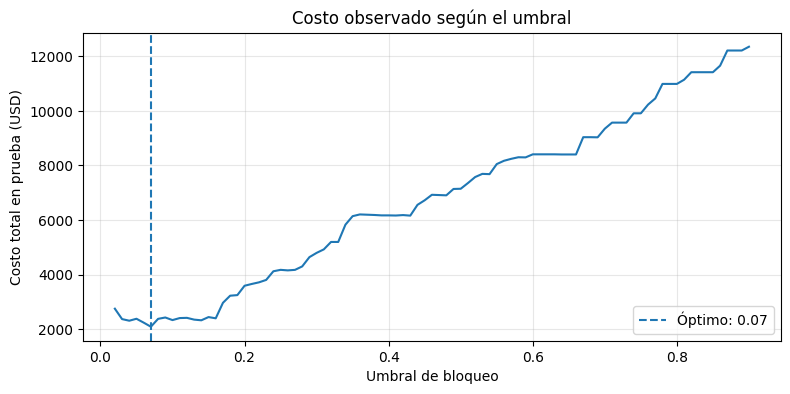

Umbral óptimo: 0.07 | costo: USD 2,084.96
No bloquear: USD 15,507.16 | Bloquear todo: USD 4,010.00
Costo con 200 muestras: media USD 2,214.40, IC90 USD [2,044.82, 2,422.23]
Ahorro observado frente a no bloquear: USD 13,422.20


In [10]:
# Identificar el monto real en los datos, sin inventar valores
col_monto = next((c for c in df.columns if c.lower() in ['monto', 'monto_usd', 'valor', 'importe', 'amount']), None)
if col_monto is None:
    raise ValueError('No se encontró el monto de transacción: ' + str(df.columns.tolist()))
# Reconstruir las filas de prueba usando los índices de la partición fija
montos_test = df.loc[X_test.index, col_monto].to_numpy(dtype=float)
y_real = y_test.to_numpy(dtype=int)
def costo_total(prob, umbral):
    bloquear = prob >= umbral
    return float(np.where(bloquear, (1-y_real)*5, y_real*montos_test).sum())
umbrales = np.round(np.arange(0.02, 0.901, 0.01), 2)
costos = np.array([costo_total(p_bayes, u) for u in umbrales])
pos = int(np.argmin(costos))
umbral_optimo = float(umbrales[pos])
costo_optimo = float(costos[pos])
costo_nada = float((y_real * montos_test).sum())
costo_todo = float(((1-y_real)*5).sum())
plt.figure(figsize=(9,4))
plt.plot(umbrales, costos)
plt.axvline(umbral_optimo, linestyle='--', label=f'Óptimo: {umbral_optimo:.2f}')
plt.xlabel('Umbral de bloqueo'); plt.ylabel('Costo total en prueba (USD)')
plt.title('Costo observado según el umbral'); plt.legend(); plt.grid(alpha=0.3)
plt.show()
# Muestras de la posterior; cada una produce un vector de probabilidades diferente
indices = np.linspace(0, len(prob_posteriores)-1, 200, dtype=int)
costos_posteriores = np.array([costo_total(prob_posteriores[i], umbral_optimo) for i in indices])
media_costo = float(costos_posteriores.mean())
intervalo_costo = np.quantile(costos_posteriores, [0.05,0.95])
print(f'Umbral óptimo: {umbral_optimo:.2f} | costo: USD {costo_optimo:,.2f}')
print(f'No bloquear: USD {costo_nada:,.2f} | Bloquear todo: USD {costo_todo:,.2f}')
print(f'Costo con 200 muestras: media USD {media_costo:,.2f}, IC90 USD [{intervalo_costo[0]:,.2f}, {intervalo_costo[1]:,.2f}]')
print(f'Ahorro observado frente a no bloquear: USD {costo_nada-costo_optimo:,.2f}')


**✍️ Respuesta:** Se eligió el umbral que minimiza el costo observado en el conjunto de prueba, dentro del rango 0,02–0,90. Se comparó su costo con no bloquear ninguna transacción y bloquearlas todas. El promedio y el intervalo del 90 % obtenidos con 200 muestras posteriores muestran cuánto puede variar el costo debido a la incertidumbre de los parámetros. El umbral óptimo puede depender del monto: un fraude de mayor valor implica una pérdida potencial mayor, mientras que bloquear una operación legítima mantiene un costo fijo de USD 5. El umbral elegido sobre prueba es exploratorio y debería validarse en un conjunto independiente antes de aplicarlo en producción.

In [11]:
# Informe final con resultados obtenidos al ejecutar el cuaderno
mejor_auc = comparacion.loc[comparacion.AUC.idxmax(), 'modelo']
mejor_brier = comparacion.loc[comparacion.Brier.idxmin(), 'modelo']
top2 = odds.reindex(odds.coeficiente.abs().sort_values(ascending=False).index).head(2)
provs_peq = resumen_prov.sort_values('n').head(3).index.tolist()
recomendado = mejor_brier  # la decisión económica requiere probabilidades confiables
informe = f"""INFORME EJECUTIVO — COMITÉ DE RIESGOS DE PAGOYA
Responsable: Cueva Evelyn

1. HALLAZGOS
Se analizó una base simulada de {len(df):,} transacciones, con tasa de fraude de {df.fraude.mean():.2%}.
Las dos variables con mayor coeficiente estandarizado en valor absoluto fueron
{top2.iloc[0]['variable']} (OR={top2.iloc[0]['odds_ratio']:.3f}) y
{top2.iloc[1]['variable']} (OR={top2.iloc[1]['odds_ratio']:.3f}).
El modelo que mejor discrimina es {mejor_auc} (AUC Bayes={comparacion.loc[0,'AUC']:.3f};
XGBoost={comparacion.loc[1,'AUC']:.3f}). El menor Brier corresponde a {mejor_brier}
(Bayes={comparacion.loc[0,'Brier']:.4f}; XGBoost={comparacion.loc[1,'Brier']:.4f}).
El modelo jerárquico estima una dispersión provincial sigma={media_sigma:.3f} en escala log-odds.
Las provincias con menos observaciones incluyen: {', '.join(map(str,provs_peq))}.
Sus tasas deben interpretarse con los intervalos creíbles y la contracción parcial.

2. RECOMENDACIÓN
En el conjunto de prueba, el umbral que minimizó el costo observado fue {umbral_optimo:.2f}.
Su costo fue USD {costo_optimo:,.2f}, frente a USD {costo_nada:,.2f} si no se bloquea
ninguna transacción y USD {costo_todo:,.2f} si se bloquean todas.
El ahorro observado frente a no bloquear fue USD {costo_nada-costo_optimo:,.2f}.
Con 200 muestras posteriores, el costo medio fue USD {media_costo:,.2f}, con intervalo
central del 90 % de USD {intervalo_costo[0]:,.2f} a USD {intervalo_costo[1]:,.2f}.
Para decisiones basadas en probabilidades se priorizaría {recomendado} por su Brier;
el otro modelo puede servir de contraste en capacidad de discriminación.
Antes de producción, calibrar y seleccionar el umbral en validación independiente.

3. LIMITACIONES Y RIESGOS
Los datos son simulados y no representan necesariamente la operación real.
Pueden faltar señales de fraude, historial del cliente y patrones de red.
La hora es cíclica y no se representa adecuadamente como predictor lineal.
El fraude cambia con el tiempo; se requiere seguimiento de AUC, Brier,
calibración por segmentos, falsos bloqueos, costos y deriva de datos.
Los costos y el umbral se estimaron sobre prueba, por lo que podrían ser optimistas.
"""
print(informe)

NameError: name 'resumen_prov' is not defined

---
# Informe final con resultados obtenidos al ejecutar el cuaderno
mejor_auc = comparacion.loc[comparacion.AUC.idxmax(), 'modelo']
mejor_brier = comparacion.loc[comparacion.Brier.idxmin(), 'modelo']
top2 = odds.reindex(odds.coeficiente.abs().sort_values(ascending=False).index).head(2)
provs_peq = resumen_prov.sort_values('n').head(3).index.tolist()
recomendado = mejor_brier  # la decisión económica requiere probabilidades confiables
informe = f"""INFORME EJECUTIVO — COMITÉ DE RIESGOS DE PAGOYA
Responsable: Cueva Evelyn

1. HALLAZGOS
Se analizó una base simulada de {len(df):,} transacciones, con tasa de fraude de {df.fraude.mean():.2%}.
Las dos variables con mayor coeficiente estandarizado en valor absoluto fueron
{top2.iloc[0]['variable']} (OR={top2.iloc[0]['odds_ratio']:.3f}) y
{top2.iloc[1]['variable']} (OR={top2.iloc[1]['odds_ratio']:.3f}).
El modelo que mejor discrimina es {mejor_auc} (AUC Bayes={comparacion.loc[0,'AUC']:.3f};
XGBoost={comparacion.loc[1,'AUC']:.3f}). El menor Brier corresponde a {mejor_brier}
(Bayes={comparacion.loc[0,'Brier']:.4f}; XGBoost={comparacion.loc[1,'Brier']:.4f}).
El modelo jerárquico estima una dispersión provincial sigma={media_sigma:.3f} en escala log-odds.
Las provincias con menos observaciones incluyen: {', '.join(map(str,provs_peq))}.
Sus tasas deben interpretarse con los intervalos creíbles y la contracción parcial.

2. RECOMENDACIÓN
En el conjunto de prueba, el umbral que minimizó el costo observado fue {umbral_optimo:.2f}.
Su costo fue USD {costo_optimo:,.2f}, frente a USD {costo_nada:,.2f} si no se bloquea
ninguna transacción y USD {costo_todo:,.2f} si se bloquean todas.
El ahorro observado frente a no bloquear fue USD {costo_nada-costo_optimo:,.2f}.
Con 200 muestras posteriores, el costo medio fue USD {media_costo:,.2f}, con intervalo
central del 90 % de USD {intervalo_costo[0]:,.2f} a USD {intervalo_costo[1]:,.2f}.
Para decisiones basadas en probabilidades se priorizaría {recomendado} por su Brier;
el otro modelo puede servir de contraste en capacidad de discriminación.
Antes de producción, calibrar y seleccionar el umbral en validación independiente.

3. LIMITACIONES Y RIESGOS
Los datos son simulados y no representan necesariamente la operación real.
Pueden faltar señales de fraude, historial del cliente y patrones de red.
La hora es cíclica y no se representa adecuadamente como predictor lineal.
El fraude cambia con el tiempo; se requiere seguimiento de AUC, Brier,
calibración por segmentos, falsos bloqueos, costos y deriva de datos.
Los costos y el umbral se estimaron sobre prueba, por lo que podrían ser optimistas.
"""
print(informe)